In [1]:
# Step 2: Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score, accuracy_score, classification_report
from sklearn.model_selection import train_test_split
import joblib

In [2]:
# Step 1: Load raw dataset
df = pd.read_csv("data/cleaned_finance_data.csv")

In [3]:
# Step 2: Add 'age' column
df["age"] = np.random.randint(20, 60, size=len(df))

In [6]:
# Step 3: Define features and target
X = df[["age", "household_income_usd", "net_worth_usd"]]
y = df["trust_score_dynamic_1_100"]   # <-- replace with your actual target column

In [3]:
# Step 3: Load preprocessed data
X_train = pd.read_csv("data/X_train.csv")
X_test = pd.read_csv("data/X_test.csv")
y_train = pd.read_csv("data/y_train.csv").squeeze()  # convert to Series
y_test = pd.read_csv("data/y_test.csv").squeeze()

In [7]:
# Step 4: Train/test split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [4]:
print("Training set:", X_train.shape, "Testing set:", X_test.shape)

Training set: (8000, 36) Testing set: (2000, 36)


In [8]:
# Step 5: Train Random Forest Regressor
rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)
rf_reg.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease o

In [9]:
# Step 6: Evaluate model
y_pred = rf_reg.predict(X_test)
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))

MSE: 66.90749235
R2 Score: -0.01635452740688237


In [ ]:
# Step 7: Save trained model
joblib.dump(rf_reg, "random_forest_model.pkl",compress=9)
print("✅ Model retrained and saved as models/random_forest_model.pkl")

✅ Model retrained and saved as models/random_forest_model.pkl


In [5]:
# Step 4: Choose model type (Regression or Classification)
# If target is numeric (e.g., trust_score_dynamic_1_100), use regression
if np.issubdtype(y_train.dtype, np.number):
    print("🔹 Target is numeric → Regression models")

    # Linear Regression
    lin_reg = LinearRegression()
    lin_reg.fit(X_train, y_train)
    y_pred_lr = lin_reg.predict(X_test)

    mse_lr = mean_squared_error(y_test, y_pred_lr)
    rmse_lr = np.sqrt(mse_lr)

    print("Linear Regression R^2:", r2_score(y_test, y_pred_lr))
    print("Linear Regression RMSE:", rmse_lr)

    # Random Forest Regressor
    rf_reg = RandomForestRegressor(random_state=42)
    rf_reg.fit(X_train, y_train)
    y_pred_rf = rf_reg.predict(X_test)

    mse_rf = mean_squared_error(y_test, y_pred_rf)
    rmse_rf = np.sqrt(mse_rf)

    print("Random Forest R^2:", r2_score(y_test, y_pred_rf))
    print("Random Forest RMSE:", rmse_rf)

else:
    print("🔹 Target is categorical → Classification models")

    
    # Logistic Regression
    log_reg = LogisticRegression(max_iter=1000)
    log_reg.fit(X_train, y_train)
    y_pred_lr = log_reg.predict(X_test)

    print("Logistic Regression Accuracy:", accuracy_score(y_test, y_pred_lr))
    print("Classification Report:\n", classification_report(y_test, y_pred_lr))

    # Random Forest Classifier
    rf_clf = RandomForestClassifier(random_state=42)
    rf_clf.fit(X_train, y_train)
    y_pred_rf = rf_clf.predict(X_test)

    print("Random Forest Accuracy:", accuracy_score(y_test, y_pred_rf))
    print("Classification Report:\n", classification_report(y_test, y_pred_rf))



🔹 Target is numeric → Regression models
Linear Regression R^2: 0.6776605968083576
Linear Regression RMSE: 0.568000057306336
Random Forest R^2: 0.7341588608069181
Random Forest RMSE: 0.515825461553286


In [9]:
import joblib

# Save trained model
joblib.dump(rf_reg, "random_forest_model.pkl")

print("✅ Model saved as .pkl file")


✅ Model and preprocessing objects saved as .pkl files


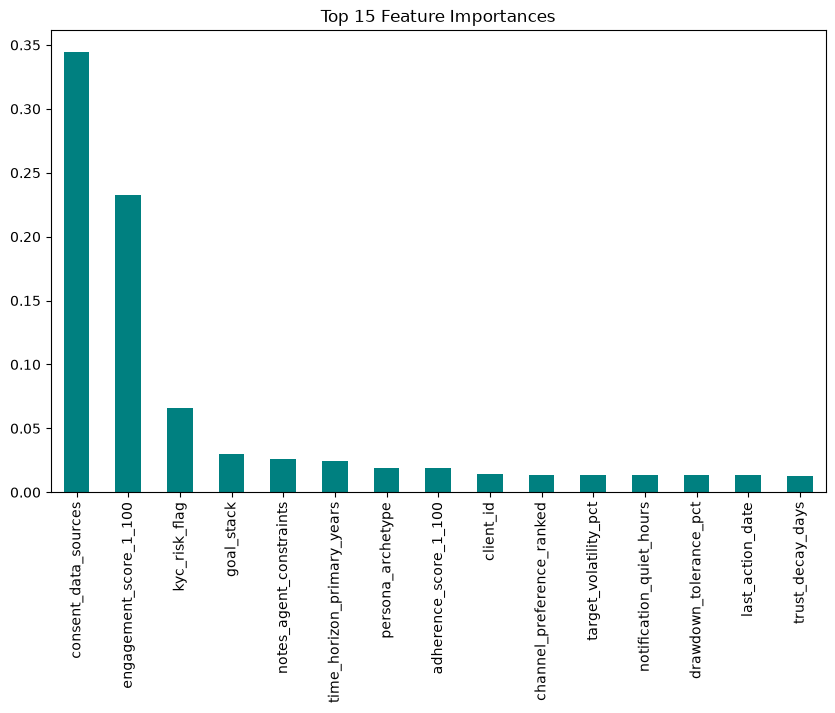

✅ Model training and evaluation complete


In [6]:
# Step 5: Feature importance (for Random Forest)
if np.issubdtype(y_train.dtype, np.number):
    importances = rf_reg.feature_importances_
else:
    importances = rf_clf.feature_importances_

feat_importances = pd.Series(importances, index=X_train.columns).sort_values(ascending=False)
plt.figure(figsize=(10,6))
feat_importances.head(15).plot(kind="bar", color="teal")
plt.title("Top 15 Feature Importances")
plt.show()

print("✅ Model training and evaluation complete")